# Lojistik Regresyon ile Cinsiyet Tahmini (Sınıflandırma)

Bu çalışma kitabında, `ayakkabi_numarasi.xlsx` veri kümesinde yer alan **Kilo(kg)**, **Boy(metre)**, **Yaş** ve **Ayakkabı Numarası** bağımsız değişkenleri kullanılarak hedef değişken olan **Cinsiyet(E veya K)** verisini tahmin eden bir **Lojistik Regresyon (*Logistic Regression*)** sınıflandırma modeli adım adım inşa edilecektir.

### İşlem Akışı Adımları:
1. **Kütüphanelerin Yüklenmesi**
2. **Veri Setinin Yüklenmesi ve Keşifsel Veri Analizi (EDA)**
3. **Veri Ön İşleme (Data Preprocessing)**
4. **Eğitim ve Test Kümelerine Ayırma ve Ölçeklendirme**
5. **Lojistik Regresyon Modelinin Eğitilmesi**
6. **Modelin Değerlendirilmesi (Karmaşıklık Matrisi ve Sınıflandırma Raporu)**
7. **Örnek Girdilerle Yeni Tahmin Yapma**

## 1. Gerekli Kütüphanelerin Yüklenmesi
Veri analizi, özellik ölçeklendirme, lojistik regresyon modellemesi ve sınıflandırma metrikleri için gerekli kütüphaneleri içe aktarıyoruz.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler#0-1 arası veriyi normalize eder.
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Grafik ayarları
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (7, 5)

## 2. Veri Setinin Yüklenmesi ve Keşifsel Veri Analizi (EDA)
Excel dosyasından veriyi okuyor, ilk satırları ve sınıf dağılımını inceliyoruz.

In [3]:
# Excel dosyasını okuma
df = pd.read_excel('ayakkabi_numarasi.xlsx')

# İlk 5 satırı görüntüleme
print("--- İlk 5 Satır ---")
display(df.head())

# Cinsiyet sınıf dağılımı
print("\n--- Sınıf Dağılımı ---")
print(df['Cinsiyet(E veya K)'].value_counts())

--- İlk 5 Satır ---


,Kilo(kg),Boy(metre),Yaş,Cinsiyet(E veya K),Ayakkabı Numarası
0,85,1.74,42,E,41
1,44,1.40,10,E,36
2,32,1.38,11,E,36
3,48,1.46,11,E,37
4,75,1.62,47,E,42



--- Sınıf Dağılımı ---
Cinsiyet(E veya K)
E    31
K    27
Name: count, dtype: int64


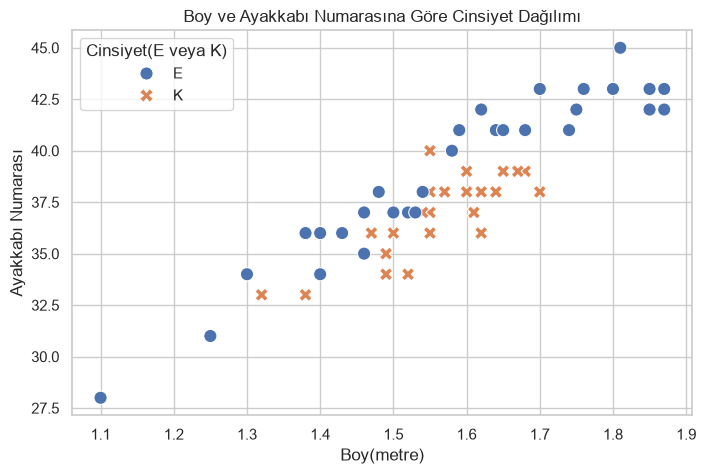

In [4]:
# Boy ve Ayakkabı Numarasına göre Cinsiyet dağılımının görselleştirilmesi
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df, x='Boy(metre)', y='Ayakkabı Numarası', 
    hue='Cinsiyet(E veya K)', style='Cinsiyet(E veya K)', s=90
)
plt.title('Boy ve Ayakkabı Numarasına Göre Cinsiyet Dağılımı')
plt.show()

## 3. Veri Ön İşleme (Data Preprocessing)
- Hedef değişkenimiz olan `Cinsiyet(E veya K)` sütununu ikili (binary) sayısal hedefe dönüştürüyoruz (`E = 1`, `K = 0`).
- Bağımsız değişkenleri ($X$: Kilo, Boy, Yaş, Ayakkabı Numarası) ve bağımlı hedef değişkeni ($y$: Cinsiyet_E) ayırıyoruz.

In [5]:
# Hedef değişkeni ikili sayısal formata kodlama (Erkek: 1, Kadın: 0)
df['Cinsiyet_E'] = (df['Cinsiyet(E veya K)'] == 'E').astype(int)

# Bağımsız değişkenler (X) ve bağımlı değişken (y)
feature_cols = ['Kilo(kg)', 'Boy(metre)', 'Yaş', 'Ayakkabı Numarası']
X = df[feature_cols]
y = df['Cinsiyet_E']

print("X Şekli:", X.shape)
print("y Şekli:", y.shape)
X.head()

X Şekli: (58, 4)
y Şekli: (58,)


,Kilo(kg),Boy(metre),Yaş,Ayakkabı Numarası
0,85,1.74,42,41
1,44,1.40,10,36
2,32,1.38,11,36
3,48,1.46,11,37
4,75,1.62,47,42


## 4. Eğitim ve Test Kümelerine Ayırma ve Ölçeklendirme
Veriyi %80 Eğitim ve %20 Test olarak ayırıyoruz. Lojistik Regresyon, optimizasyon sürecinde farklı ölçekteki değişkenlerden (ör. `Boy` metre cinsinden 1.70 iken `Kilo` 75) etkilenmemesi için `StandardScaler` ile standartlaştırılır.

In [10]:
# Eğitim ve test kümelerine ayırma
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.16, random_state=42
)

# Özellikleri standartlaştırma (Ortalaması 0, Standart Sapması 1)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Eğitim seti boyutu: {X_train.shape[0]} örnek")
print(f"Test seti boyutu:   {X_test.shape[0]} örnek")

Eğitim seti boyutu: 48 örnek
Test seti boyutu:   10 örnek


## 5. Lojistik Regresyon Modelinin Eğitilmesi
Lojistik Regresyon, doğrusal kombinasyonu **Sigmoid (Lojistik)** fonksiyonundan geçirerek gözlemin Erkek (`1`) veya Kadın (`0`) olma olasılığını ($P(y=1|X)$) hesaplar:

$$\sigma(z) = \frac{1}{1 + e^{-z}}, \quad z = \beta_0 + \beta_1 \text{Kilo} + \beta_2 \text{Boy} + \beta_3 \text{Yaş} + \beta_4 \text{AyakkabıNo}$$

In [11]:
# Lojistik Regresyon model nesnesinin oluşturulması ve eğitilmesi
model = LogisticRegression(random_state=42)
model.fit(X_train_scaled, y_train)

print("Lojistik Regresyon modeli başarıyla eğitildi.")

Lojistik Regresyon modeli başarıyla eğitildi.


## 6. Modelin Değerlendirilmesi
Sınıflandırma başarısını ölçmek için **Doğruluk (Accuracy)**, **Karmaşıklık Matrisi (Confusion Matrix)** ve **Sınıflandırma Raporu (Precision, Recall, F1-Score)** metriklerini inceliyoruz.

In [12]:
# Test seti üzerinde tahmin yapma
y_pred = model.predict(X_test_scaled)

# Doğruluk (Accuracy) skoru
acc = accuracy_score(y_test, y_pred)
print(f"Model Doğruluk Oranı (Accuracy): %{acc * 100:.2f}\n")

# Detaylı Sınıflandırma Raporu
print("--- Sınıflandırma Raporu ---")
print(classification_report(y_test, y_pred, target_names=['Kadın (0)', 'Erkek (1)']))

Model Doğruluk Oranı (Accuracy): %70.00

--- Sınıflandırma Raporu ---
              precision    recall  f1-score   support

   Kadın (0)       1.00      0.50      0.67         6
   Erkek (1)       0.57      1.00      0.73         4

    accuracy                           0.70        10
   macro avg       0.79      0.75      0.70        10
weighted avg       0.83      0.70      0.69        10



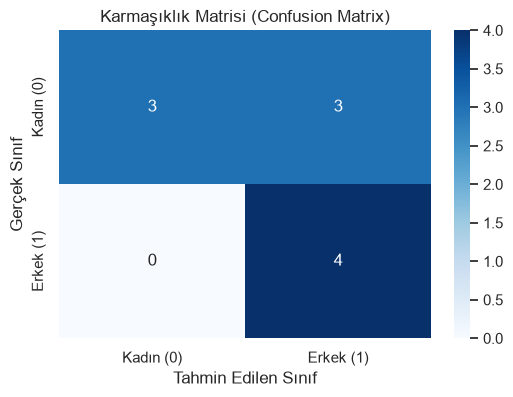

In [13]:
# Karmaşıklık Matrisinin (Confusion Matrix) Görselleştirilmesi
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Kadın (0)', 'Erkek (1)'],
    yticklabels=['Kadın (0)', 'Erkek (1)']
)
plt.xlabel('Tahmin Edilen Sınıf')
plt.ylabel('Gerçek Sınıf')
plt.title('Karmaşıklık Matrisi (Confusion Matrix)')
plt.show()

## 7. Örnek Girdilerle Yeni Tahmin Yapma
Eğitilmiş modeli kullanarak yeni bireylerin fiziksel verilerinden cinsiyet tahminini ve modelin hesapladığı olasılık değerlerini (`predict_proba`) inceliyoruz.

In [14]:
# Örnek yeni bireyler: [Kilo(kg), Boy(metre), Yaş, Ayakkabı Numarası]
yeni_ornekler = pd.DataFrame([
    {'Kilo(kg)': 78, 'Boy(metre)': 1.76, 'Yaş': 30, 'Ayakkabı Numarası': 43},
    {'Kilo(kg)': 56, 'Boy(metre)': 1.63, 'Yaş': 25, 'Ayakkabı Numarası': 37}
])

# Yeni verileri eğitimdeki scaler ile ölçeklendirme
yeni_ornekler_scaled = scaler.transform(yeni_ornekler)

# Sınıf ve olasılık tahminleri
sinif_tahminleri = model.predict(yeni_ornekler_scaled)
olasiliklar = model.predict_proba(yeni_ornekler_scaled)

for i, row in yeni_ornekler.iterrows():
    tahmin_etiket = 'Erkek (E)' if sinif_tahminleri[i] == 1 else 'Kadın (K)'
    kadin_olasilik = olasiliklar[i][0] * 100
    erkek_olasilik = olasiliklar[i][1] * 100
    print(f"Birey {i+1} (Boy: {row['Boy(metre)']}m, Kilo: {row['Kilo(kg)']}kg, Yaş: {row['Yaş']}, Ayakkabı No: {row['Ayakkabı Numarası']})\n"
          f" -> Tahmin Edilen Cinsiyet: {tahmin_etiket} "
          f"(Olasılıklar -> Kadın: %{kadin_olasilik:.1f}, Erkek: %{erkek_olasilik:.1f})\n")

Birey 1 (Boy: 1.76m, Kilo: 78.0kg, Yaş: 30.0, Ayakkabı No: 43.0)
 -> Tahmin Edilen Cinsiyet: Erkek (E) (Olasılıklar -> Kadın: %14.6, Erkek: %85.4)

Birey 2 (Boy: 1.63m, Kilo: 56.0kg, Yaş: 25.0, Ayakkabı No: 37.0)
 -> Tahmin Edilen Cinsiyet: Kadın (K) (Olasılıklar -> Kadın: %60.9, Erkek: %39.1)

